In [307]:
import numpy as np
import matplotlib.pyplot as plt

def plot_voxel_by_index(skel, flat_idx, cmap='gray'):
    """
    Visualize a voxel in a 3D skeleton array by its flattened index.

    Parameters
    ----------
    skel : np.ndarray
        3D array (e.g., skeleton volume).
    flat_idx : int
        Flattened index from np.flatnonzero(skel).
    cmap : str, optional
        Colormap for display (default 'gray').
    """
    # Get (y, x, z) coordinates from flat index
    y, x, z = np.unravel_index(flat_idx, skel.shape)

    # Show the correct slice
    plt.imshow(skel[:, :, z], cmap=cmap, origin='upper')

    # Highlight voxel
    plt.scatter(x, y, color='red', s=100, marker='s', label=f'Flat idx {flat_idx}')
    plt.legend()
    plt.colorbar()
    plt.title(f'z = {z}  |  voxel = ({y}, {x}, {z})')
    plt.show()


In [308]:
import numpy as np

def pk_get_nh_idx(img, indices):
    """
    Python translation of MATLAB pk_get_nh_idx.
    - img: 3D numpy array (shape (W,H,D)). Should be padded externally (like MATLAB padarray).
    - indices: 1D array-like of linear indices (numpy 0-based indices into img.ravel()).
    Returns:
      nhood: (N,27) int64 array. Each row contains 27 0-based linear indices for that voxel's 3x3x3 neighborhood.
    """
    indices = np.asarray(indices, dtype=np.int64)
    if indices.ndim != 1:
        indices = indices.ravel()

    w, h, d = img.shape
    # unravel to coordinates (0-based)
    x, y, z = np.unravel_index(indices, (w, h, d))
    # prepare output
    n = len(indices)
    nhood = np.empty((n, 27), dtype=np.int64)

    col = 0
    # MATLAB loops xx=1:3,yy=1:3,zz=1:3 and uses x+xx-2 etc.
    # We loop offsets (-1,0,+1) which corresponds to xx-2 in MATLAB.
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            for dz in (-1, 0, 1):
                # neighbor coordinates
                nx = x + dx
                ny = y + dy
                nz = z + dz
                # convert to linear index (0-based)
                nhood[:, col] = np.ravel_multi_index((nx, ny, nz), (w, h, d))
                col += 1

    return nhood

def pk_get_nh(img, indices):
    """
    Python translation of MATLAB pk_get_nh.
    - img: 3D numpy array (dtype can be bool or int). Should be padded externally.
    - indices: 1D array-like of linear indices (0-based).
    Returns:
      nhood: (N,27) boolean numpy array; True if voxel is foreground/non-zero.
    """
    indices = np.asarray(indices, dtype=np.int64).ravel()
    w, h, d = img.shape
    x, y, z = np.unravel_index(indices, (w, h, d))

    n = len(indices)
    nhood = np.empty((n, 27), dtype=bool)

    col = 0
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            for dz in (-1, 0, 1):
                nx = x + dx
                ny = y + dy
                nz = z + dz
                linear_idx = np.ravel_multi_index((nx, ny, nz), (w, h, d))
                # pick values from img by flat indexing
                nhood[:, col] = img.ravel()[linear_idx].astype(bool)
                col += 1

    return nhood

def pk_follow_link(skel2, nodes, curr_node_cluster_idx, curr_node_idx, can_idx, cans, c2n):
    """
    Returns the path from the current node and its current canal voxel neighbor to another node
    (endpoint or not).

    Inputs: 
        - skel2 [np.ndarray]: skeletonized image with identified node clusters (clusters have unique id [2, inf],
          all 1s are canal voxels, and all 0s are background voxels)
        - nodes [list[node_cluster]]: list of all node_clusters in the network
        - curr_node_cluster_idx [int]: index of the current node cluster
        - curr_node_idx [int]: index of the current voxel in the current node cluster
        - can_idx [int]: current canal voxel index
        - cans [np.ndarray or list]: canal voxel connections
        - c2n [np.ndarray or list]: mapping from canal voxel index to neighbor canal index
    """
    path = []
    ep = 0

    # ensure int
    path.append(int(nodes[curr_node_cluster_idx].nodes_idx[curr_node_idx]))

    done = False
    while not done:
        next_cand = int(c2n[can_idx] - 1)
        cand = int(cans[next_cand][1])

        # switch to other canal voxel neighbor
        if cand == path[-1]:
            cand = int(cans[next_cand][2])

        if skel2.flat[cand] > 1:
            path.append(int(can_idx))
            path.append(int(cand))
            n_idx = int(skel2.flat[cand] - 2)

            ep = int(nodes[n_idx].ep)
            done = True

        else:
            path.append(int(curr_node_idx))
            curr_node_idx = int(cand)

    return (path, n_idx, ep)

In [309]:
class node_cluster:
    def __init__(self, nodes_idx: list[int], ep: int):
        self.nodes_idx = nodes_idx
        self.links = []
        self.conn = [] # list of indices (w respect to the node list) of all endpoint node voxels (connections)
        self.ep = ep
        self.comx = None
        self.comy = None
        self.comz = None
        self.label = None

    def find_center_mass(self, skel_dim: tuple[int, int, int]) -> None:
        x, y, z = np.unravel_index(self.nodes_idx, skel_dim)
        self.comx = np.mean(x)
        self.comy = np.mean(y)
        self.comz = np.mean(z)
    
    def assign_label(self, lm: np.ndarray):
        self.label = lm.ravel()[self.nodes_idx[0]]

    def assign_links(self, l_idx: int) -> None:
        self.links.append(l_idx)

    def assign_conn(self, ep_idx: int) -> None:
        self.conn.append(ep_idx)

    def __str__(self):
        return (
            f"node_cluster(\n"
            f"  nodes_idx: {self.nodes_idx}\n"
            f"  links: {self.links}\n"
            f"  conn: {self.conn}\n"
            f"  ep: {self.ep}\n"
            f"  comx: {self.comx}\n"
            f"  comy: {self.comy}\n"
            f"  comz: {self.comz}\n"
            f"  label: {self.label}\n"
            f")"
        )

class Link:
    def __init__(self, start: int, end: int, path: list[int], label: int) -> None:
        self.start = start
        self.end = end
        self.path = path
        self.label = None
        self.links = None
        self.conn = None

    def __str__(self):
        return (
            f"Link(\n"
            f"  start: {self.start}\n"
            f"  end: {self.end}\n"
            f"  path: {self.path}\n"
            f"  label: {self.label}\n"
            f"  links: {self.links}\n"
            f"  conn: {self.conn}\n"
            f")"
        )

In [ ]:
from scipy.ndimage import label
import numpy as np

thr = 0 # this will be a parameter to the function

skel = np.array([
    [1, 0, 0, 0, 0],
    [1, 1, 1, 0, 0],
    [1, 0, 0, 0, 0],
    [0, 0, 0, 0, 1]
])

# pad volume with zeros
skel = skel[:, :, np.newaxis]
skel = np.pad(skel, pad_width=1, mode='constant')

# label connected components 
lm, num_components= label(skel, structure=np.ones((3, 3, 3)))

skel2 = skel.astype(np.uint16) # needed for labeling nodes etc.

# all foreground (True) voxels, as flat indices
list_canal = np.flatnonzero(skel)

# if image contains no skeletonized data, return empty elements
if len(list_canal) == 0:
    raise ValueError("No skeletonized data: the input 3D mask contains no foreground voxels.")

# 26-nh of all canal voxels
nh = pk_get_nh(skel, list_canal)       # shape: (len(list_canal), 27)

# 26-nh indices of all canal voxels
nhi = pk_get_nh_idx(skel, list_canal)  # shape: (len(list_canal), 27)

# num of 26-nb of each skel voxel + 1
sum_nh = np.sum(nh.astype(bool), axis=1)

# node/endpoint/canal assignment
nodes = list_canal[sum_nh > 3] # all canal voxels with >2 nb are nodes -> branching points
ep    = list_canal[sum_nh == 2] # all canal voxels with exactly one nb are end nodes -> endpoints
cans  = list_canal[sum_nh == 3] # all canal voxels with exactly 2 nb -> segments

# Nx3 matrix with the 2 neighbors of each canal voxel
if cans.size > 0:
    can_nh_idx = pk_get_nh_idx(skel, cans)
    can_nh = pk_get_nh(skel, cans)

    # remove center of 3x3 cube
    can_nh_idx = np.delete(can_nh_idx, 13, axis=1)
    can_nh = np.delete(can_nh, 13, axis=1)

    # keep only the two existing foreground voxels
    can_nb = np.sort(can_nh * can_nh_idx, axis=1)
    can_nb = can_nb[:, -2:]  # keep last two columns

    # add neighbours to canalicular voxel list (this might include nodes)
    cans = np.column_stack([cans, can_nb])
else:
    cans = np.empty((0, 3), dtype=int)

# group clusters of node voxels to nodes
node, link = [],[]

# add node metadata
tmp = np.zeros(skel.shape, dtype=bool)
tmp.ravel()[nodes] = True
labelimg, num_clustered_nodes = label(tmp, structure=np.ones((3,3,3))) # number of unique nodes
cluster_indices = [np.flatnonzero(labelimg == i) for i in range(1, num_clustered_nodes+1)]

for i in range(num_clustered_nodes):
    l = lm.flatten()[cluster_indices]
    new_node = node_cluster(cluster_indices[i], 0)
    new_node.find_center_mass(skel.shape)
    new_node.assign_label(lm)
    node.append(new_node)

    # assign index to node voxels in skel2
    id = i + 2
    skel2.ravel()[new_node.nodes_idx] = id

# add endpoint metadata
tmp = np.zeros(skel.shape, dtype=bool)
tmp.ravel()[ep] = True
labelimg, num_clustered_nodes = label(tmp, structure=np.ones((3,3,3))) # number of unique nodes
cluster_indices = [np.flatnonzero(labelimg == i) for i in range(1, num_clustered_nodes+1)]


for i in range(num_clustered_nodes):
    l = lm.flatten()[cluster_indices]
    new_node = node_cluster(cluster_indices[i], 0)
    new_node.find_center_mass(skel.shape)
    new_node.assign_label(lm)
    node.append(new_node)

    # assign index to node voxels in skel2
    id = len(node) + 1
    skel2.ravel()[new_node.nodes_idx] = id

l_idx = 0

c2n = np.zeros(skel.shape, dtype=int)
c2n_flat = c2n.ravel()
c2n_flat[cans[:, 0]] = np.arange(1, cans.shape[0] + 1)
c2n = c2n_flat

s2n = np.zeros(skel.shape, dtype=int)
s2n_flat = s2n.ravel()
s2n_flat[nhi[:, 13]] = np.arange(1, nhi.shape[0] + 1)
s2n = s2n_flat

for curr_cluster_node_idx in range(len(node)):
    link_indices = s2n[node[curr_cluster_node_idx].nodes_idx] - 1

    for link_idx in range(len(link_indices)):
        link_cands = nhi[link_indices[link_idx], nh[link_indices[link_idx], :] == 1]

        # short branches with 1 endpoint
        ep_cands = np.intersect1d(link_cands, ep)
        link_cands = link_cands[skel2.ravel()[link_cands] == 1]
        link_cands = np.intersect1d(link_cands, cans[:, 0])

        for can_idx in range(len(link_cands)):
            print(f"=====Iter number {curr_cluster_node_idx} ====")
            print(f"skel2 shape: {getattr(skel2, 'shape', type(skel2))}")
            print(f"node: {node}")
            print(f"curr_cluster_node_idx: {curr_cluster_node_idx}")
            print(f"link_idx: {link_idx}")
            print(f"link_cands[can_idx]: {link_cands[can_idx]}")
            print(f"cans shape/type: {getattr(cans, 'shape', type(cans))}")
            print(f"c2n type/len: {type(c2n)}, len={len(c2n) if hasattr(c2n, '__len__') else 'N/A'}")
            path, end_cluster_node_idx, ept = pk_follow_link(
                skel2, node, curr_cluster_node_idx, link_idx, link_cands[can_idx], cans, c2n
            )
            print("Path:", path)
            print("==========================\n")
            # mark seen path 
            skel2.ravel()[path[1:-1]] = 0

            # remove threshold branches
            if (ept and len(path) > thr) or (not ept and curr_cluster_node_idx != end_cluster_node_idx):
                # create link structure
                print("Not printiiiiing")
                new_link = Link(curr_cluster_node_idx, 
                                end_cluster_node_idx, 
                                path, 
                                lm.ravel()[path[1:-1]])
                
                link.append(new_link)

                # udpate linkage in curr_node  
                curr_node = node[curr_cluster_node_idx]
                curr_node.links.append(l_idx)
                curr_node.conn.append(end_cluster_node_idx)

                # update linkage in end_node
                end_node = node[end_cluster_node_idx]
                end_node.links.append(l_idx)
                end_node.conn.append(curr_cluster_node_idx)

                l_idx += 1
    
    # if short branches are allowed
    if thr == 0:
        for ep_cand_idx in range(len(ep_cands)):
            val = skel2.ravel()[ep_cands[ep_cand_idx]].astype(np.int64) # avoid overflow
            ep_idx = val - 2

            if ep_idx and ep_idx != curr_cluster_node_idx:
                skel2.ravel()[ep_cands[ep_cand_idx]] = 0
                new_link = Link(curr_cluster_node_idx,
                                end_cluster_node_idx,
                                path,
                                lm.ravel()[ep_cands[ep_cand_idx]])
                link.append(new_link)
                
                curr_node = node[curr_cluster_node_idx]
                curr_node.links.append(l_idx)
                curr_node.conn.append(end_cluster_node_idx)

                end_node = node[end_cluster_node_idx]
                end_node.links.append(l_idx)
                end_node.conn.append(curr_cluster_node_idx)

                l_idx += 1

=====Iter number 0 ====
skel2 shape: (6, 7, 3)
node: [<__main__.node_cluster object at 0x119f897f0>, <__main__.node_cluster object at 0x11afefc50>]
curr_cluster_node_idx: 0
link_idx: 0
link_cands[can_idx]: 25
cans shape/type: (2, 3)
c2n type/len: <class 'numpy.ndarray'>, len=126
Path: [46, 25, 49]

=====Iter number 0 ====
skel2 shape: (6, 7, 3)
node: [<__main__.node_cluster object at 0x119f897f0>, <__main__.node_cluster object at 0x11afefc50>]
curr_cluster_node_idx: 0
link_idx: 0
link_cands[can_idx]: 67
cans shape/type: (2, 3)
c2n type/len: <class 'numpy.ndarray'>, len=126
Path: [46, 67, 49]



In [311]:
print(node[0])

node_cluster(
  nodes_idx: [46 49]
  links: [0, 0, 1]
  conn: [0, 0, 1]
  ep: 0
  comx: 2.0
  comy: 1.5
  comz: 1.0
  label: 1
)


In [312]:
print(link[0])

Link(
  start: 0
  end: 0
  path: [46, 67, 49]
  label: None
  links: None
  conn: None
)


In [313]:
np.flatnonzero(skel)

array([ 25,  46,  49,  52,  67, 100])

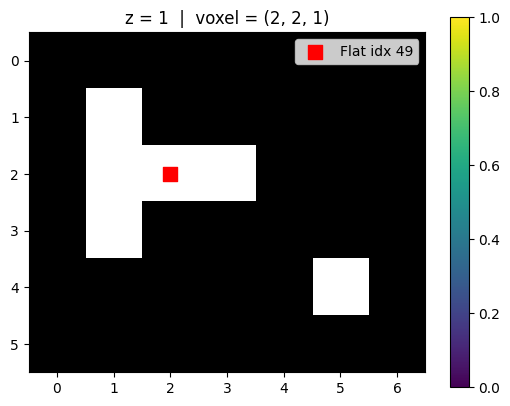

In [314]:
plot_voxel_by_index(skel, 49)